<a href="https://colab.research.google.com/github/isurika23/EN4554_Deep-Learning-for-Vision/blob/main/EN4554_Assignment02_CNN/EN4554_Assignment02_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup


## Imports and Seeds

In [1]:
import os
import random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

# fix random seeds
def set_seed(seed=42):
    random.seed(seed);
    np.random.seed(seed)
    torch.manual_seed(seed);
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


#  Dataset destination
Option 1: Google drive (Google Colab)

In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/EN4554_A2'
NUM_WORKERS = 2

Mounted at /content/drive


Option 2: root (Local machine) *-- currently commented*

In [ ]:
# PROJECT_DIR = '.'          # folder where this notebook lives
# NUM_WORKERS = 2            # on Windows, set to 0 if the DataLoader hangs or errors

In [3]:
DATA_ROOT   = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')   # save losses/accuracies here later
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Data:", DATA_ROOT, "| Results:", RESULTS_DIR)

Data: /content/drive/MyDrive/EN4554_A2/data | Results: /content/drive/MyDrive/EN4554_A2/results


Dataset: CIFAR-10 (torchvision.datasets.CIFAR10) <br/>
Training set: 45k | Validation set: 5k

## Download the dataset - `CIFAR-10`

In [4]:
raw = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)

100%|██████████| 170M/170M [51:23<00:00, 55.3kB/s]


## Split 45k/5k and compute statistics

In [5]:
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g)
train_idx = perm[:45000].tolist()
val_idx   = perm[45000:].tolist()

# Per-channel statistics from the TRAINING split only
x = torch.tensor(raw.data[train_idx]).float() / 255.0   # shape (45000, 32, 32, 3)
mean = x.mean(dim=(0, 1, 2))
std  = x.std(dim=(0, 1, 2))
print("mean:", mean, "std:", std)

mean: tensor([0.4917, 0.4823, 0.4467]) std: tensor([0.2471, 0.2435, 0.2616])


## A reusable loader function

In [6]:
normalize = T.Normalize(mean.tolist(), std.tolist())
base_tf = T.Compose([T.ToTensor(), normalize])

def get_loaders(train_tf=base_tf, batch_size=128, n_train=None):
    # Two dataset objects, so augmentation applies to train only, never to val
    train_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=train_tf)
    val_set   = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=base_tf)
    idx = train_idx if n_train is None else train_idx[:n_train]
    train_loader = DataLoader(Subset(train_set, idx), batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(42))
    val_loader = DataLoader(Subset(val_set, val_idx), batch_size=512,
                            shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader

## Sanity check

torch.Size([128, 3, 32, 32]) torch.Size([128])
mean: tensor([ 0.0016, -0.0306, -0.0233]), std: tensor([0.9923, 0.9767, 0.9602])


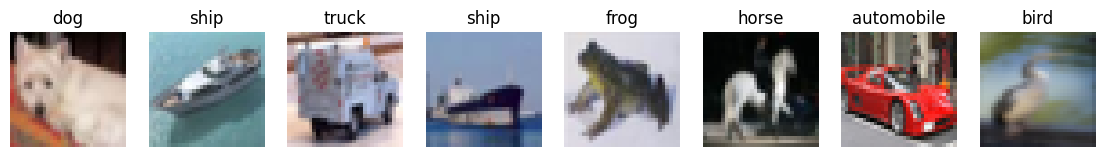

In [7]:
train_loader, val_loader = get_loaders()
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                         # expect [128, 3, 32, 32] and [128]
print(f'mean: {xb.mean(dim=(0, 2, 3))}, std: {xb.std(dim=(0, 2, 3))}')  # should be close to 0 and 1

classes = raw.classes
imgs = xb[:8] * std.view(3, 1, 1) + mean.view(3, 1, 1)   # undo normalization for display
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, imgs, yb[:8]):
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1)); ax.set_title(classes[lbl]); ax.axis('off')
plt.show()

# Task 1: Backpropogation
(a) Implement Linear, ReLU, and softmax cross-entropy with explicit `forward/backward` (no `autograd`), and assemble an MLP.<br/>
(b) Verify your gradients against `autograd` and against centred finite differences; report the relative errors. Use `torch`. allclose to check whether the gradients match. <br/>
(c) Train it with SGD on flattened `CIFAR-10` images; plot the loss and report validation accuracy. <br/>
(d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.


## (a) Linear, ReLU, Softmax cross entropy, Sigmoid Implementations

In [8]:
class Linear:
    def __init__(self, in_f, out_f, dtype=torch.float32):
        # He (Kaiming) init: std = sqrt(2 / fan_in)
        self.W = torch.randn(out_f, in_f, device=device, dtype=dtype) * (2.0 / in_f) ** 0.5
        self.b = torch.zeros(out_f, device=device, dtype=dtype)
        self.dW, self.db = None, None

    def forward(self, x):
        self.x = x                     # cache the input: backward needs it
        return x @ self.W.T + self.b   # Y = X W^T + b

    def backward(self, dout):
        self.dW = dout.T @ self.x      # shape (out, in). dout is (N, out), self.x is (N, in)
        self.db = dout.sum(dim=0)
        return dout @ self.W           # dL/dX, shape (N, in)

class ReLU:
    def forward(self, x):
        self.mask = x > 0              # boolean mask of where x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)   # σ' = σ(1-σ)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        N = logits.shape[0]
        shifted = logits - logits.max(dim=1, keepdim=True).values   # numerical stability
        exp = shifted.exp()
        sum_exp = exp.sum(dim=1, keepdim=True)
        self.probs = exp / sum_exp                                  # softmax probabilities, shape (N, 10)
        self.y = y
        log_probs = shifted - sum_exp.log()                         # log softmax = shifted - log(sum of exp)
        return -log_probs[torch.arange(N, device=logits.device), y].mean()  # mean over the batch of -log_probs at the true class

    def backward(self):
        N = self.probs.shape[0]
        d = self.probs.clone()
        d[torch.arange(N, device=d.device), self.y] -= 1   # p - onehot(y)
        return d / N                                        # /N because the loss is a mean shape (N, 10)


class MLP:
    def __init__(self, sizes, act=ReLU, dtype=torch.float32):
        # sizes = [3072, 512, 256, 10] -> Linear, act, Linear, act, Linear
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype))
            if i < len(sizes) - 2:     # no activation after the last layer
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        # pass x through every layer, return logits
        for layer in self.layers:
          x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        # start from loss_fn.backward(), go through layers in REVERSE
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def sgd_step(self, lr):
        # W -= lr * dW and b -= lr * db for every Linear
        for l in self.linears():
            l.W -= lr * l.dW
            l.b -= lr * l.db

## (b) Gradient check

### Centered Finite Difference (FD): `numerical_grad`<br/>
Adds a tiny number $\epsilon$ (eps=1e-6), calculates the forward pass to get a new loss ($L_+$), subtracts $\epsilon$ to get another loss ($L_-$), and calculates the slope using the formula $\frac{L_+ - L_-}{2\epsilon}$ for each $P_i$.

### `autograd` (AG):
The block labeled `(2) Autograd reference` sets up a parallel network using standard PyTorch operations with requires_grad=True. When `F.cross_entropy(h, y).backward()` is called, PyTorch's Autograd automatically traverses the computational graph backward to calculate the exact chain-rule gradients, storing them in W.grad and b.grad.

In [9]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def numerical_grad(net, x, y, P, eps=1e-6):
    G = torch.zeros_like(P)
    flatP, flatG = P.view(-1), G.view(-1)   # views share memory, so editing flatP edits P
    for i in range(flatP.numel()):
        old = flatP[i].item()
        flatP[i] = old + eps
        L_plus  = net.loss(x, y).item()
        flatP[i] = old - eps
        L_minus = net.loss(x, y).item()
        flatP[i] = old
        flatG[i] = (L_plus - L_minus) / (2 * eps)
    return G

def grad_check(act):
    torch.manual_seed(0)
    dt = torch.float64                       # float64 so finite differences are accurate
    net = MLP([20, 16, 16, 10], act=act, dtype=dt)
    x = torch.randn(8, 20, device=device, dtype=dt)
    y = torch.randint(0, 10, (8,), device=device)

    # (1) Our manual gradients
    net.loss(x,y)
    net.backward()

    # (2) Autograd reference: same weights, standard PyTorch ops
    torch_act = {ReLU: torch.relu, Sigmoid: torch.sigmoid}[act]
    lins = net.linears()
    Ws = [l.W.clone().requires_grad_(True) for l in lins]
    bs = [l.b.clone().requires_grad_(True) for l in lins]
    h = x
    for i, (W, b) in enumerate(zip(Ws, bs)):
        h = h @ W.T + b
        if i < len(lins) - 1:
            h = torch_act(h)
    F.cross_entropy(h, y).backward()

    print(f"\n--- {act.__name__} ---")
    print(f"{'param':<7}{'rel err vs autograd':>21}{'rel err vs FD':>16}{'allclose AG':>13}{'allclose FD':>13}")
    for i, l in enumerate(lins):
        for name, P, G, G_ag in [(f"W{i+1}", l.W, l.dW, Ws[i].grad),
                                 (f"b{i+1}", l.b, l.db, bs[i].grad)]:
            G_fd = numerical_grad(net, x, y, P)
            print(f"{name:<7}{rel_err(G, G_ag):>21.2e}{rel_err(G, G_fd):>16.2e}"
                  f"{str(torch.allclose(G, G_ag)):>13}"
                  f"{str(torch.allclose(G, G_fd, rtol=1e-4, atol=1e-6)):>13}")

grad_check(ReLU)
grad_check(Sigmoid)


--- ReLU ---
param    rel err vs autograd   rel err vs FD  allclose AG  allclose FD
W1                  1.12e-16        7.51e-10         True         True
b1                  9.17e-17        9.97e-10         True         True
W2                  4.79e-17        5.64e-10         True         True
b2                  6.10e-17        6.53e-10         True         True
W3                  4.52e-17        8.02e-10         True         True
b3                  6.91e-17        4.74e-10         True         True

--- Sigmoid ---
param    rel err vs autograd   rel err vs FD  allclose AG  allclose FD
W1                  1.17e-16        8.09e-09         True         True
b1                  7.69e-17        3.70e-09         True         True
W2                  6.11e-17        2.24e-09         True         True
b2                  7.27e-17        7.29e-10         True         True
W3                  5.54e-17        9.05e-10         True         True
b3                  6.82e-17        4.27e-10  

## (c) Train with SGD

In [10]:
def evaluate(net, loader):
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb = xb.to(device).view(xb.size(0), -1)      # flatten (B,3,32,32) -> (B,3072)
        yb = yb.to(device)
        logits = net.forward(xb)
        loss_sum += net.loss_fn.forward(logits, yb).item() * len(yb)
        correct  += (logits.argmax(dim=1) == yb).sum().item()
        total    += len(yb)
    return loss_sum / total, correct / total

set_seed(42)
train_loader, val_loader = get_loaders(batch_size=128)
net = MLP([3072, 512, 256, 10], act=ReLU)
lr, epochs = 0.05, 10
history = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}

for ep in range(epochs):
    run_loss, n = 0.0, 0
    for xb, yb in train_loader:
        xb = xb.to(device).view(xb.size(0), -1); yb = yb.to(device)
        loss = net.loss(xb, yb)   # forward + loss
        net.backward()            # backward
        net.sgd_step(lr)          # SGD step
        history['iter_loss'].append(loss.item())
        run_loss += loss.item() * len(yb); n += len(yb)
    val_loss, val_acc = evaluate(net, val_loader)
    history['train_loss'].append(run_loss / n)
    history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
    print(f"epoch {ep+1:2d} | train loss {run_loss/n:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

torch.save(history, os.path.join(RESULTS_DIR, 'task1c_history.pt'))

epoch  1 | train loss 1.706 | val loss 1.583 | val acc 0.447
epoch  2 | train loss 1.421 | val loss 1.489 | val acc 0.482
epoch  3 | train loss 1.293 | val loss 1.502 | val acc 0.477
epoch  4 | train loss 1.192 | val loss 1.471 | val acc 0.493
epoch  5 | train loss 1.101 | val loss 1.574 | val acc 0.464
epoch  6 | train loss 1.018 | val loss 1.472 | val acc 0.508
epoch  7 | train loss 0.941 | val loss 1.534 | val acc 0.487
epoch  8 | train loss 0.867 | val loss 1.502 | val acc 0.516
epoch  9 | train loss 0.800 | val loss 1.601 | val acc 0.502
epoch 10 | train loss 0.738 | val loss 1.550 | val acc 0.520


## Plotting

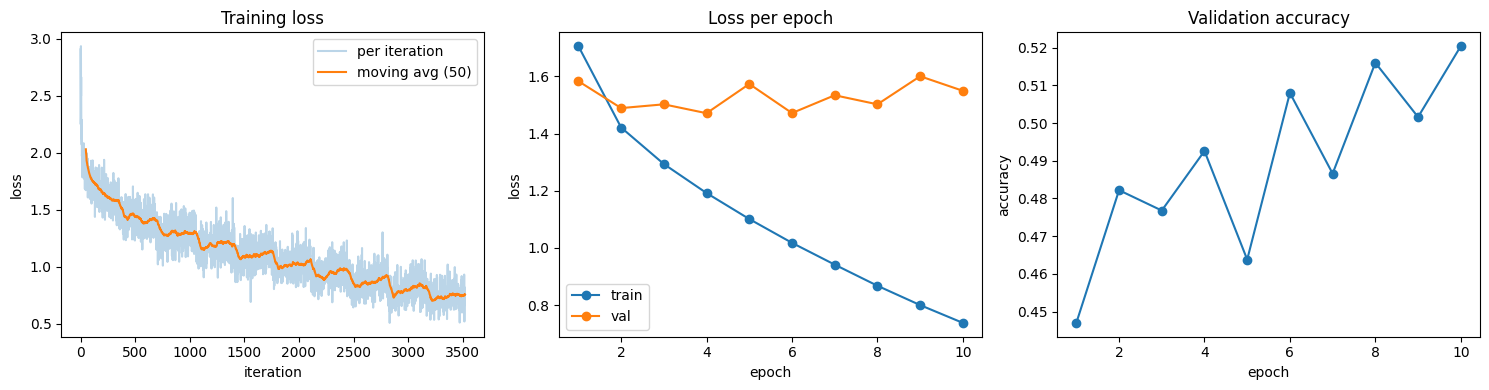

Final validation accuracy: 0.5204


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history['iter_loss'], alpha=0.3, label='per iteration')
k = 50
smooth = np.convolve(history['iter_loss'], np.ones(k) / k, mode='valid')
ax[0].plot(range(k - 1, len(history['iter_loss'])), smooth, label=f'moving avg ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss'); ax[0].legend(); ax[0].set_title('Training loss')
ep = range(1, epochs + 1)
ax[1].plot(ep, history['train_loss'], 'o-', label='train'); ax[1].plot(ep, history['val_loss'], 'o-', label='val')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss'); ax[1].legend(); ax[1].set_title('Loss per epoch')
ax[2].plot(ep, history['val_acc'], 'o-'); ax[2].set_xlabel('epoch'); ax[2].set_ylabel('accuracy')
ax[2].set_title('Validation accuracy')
plt.tight_layout(); plt.show()
print(f"Final validation accuracy: {history['val_acc'][-1]:.4f}")

#### Plots and results interpretation:
Even though the training loss is gradually decreased, the validation error and accuracy keeps fluctuating while the gap between the training and validation error keeps getting increased. This shows the overfitting of the model for the training data set rather than actually learning. With about 1.7M parameters and no regularization, the network can memorize the training images instead of learning features that generalize. The validation accuracy fluctuates because the validation set has only 5k images and the model is no longer improving consistently on unseen data.

Also the validation accurary tops at 52%, which is a comparatively low accuracy. We can argue that the reason for this is flattening of the input data, which removes the spatial details of the input.

## (d) Per-layer gradient norms at initialization

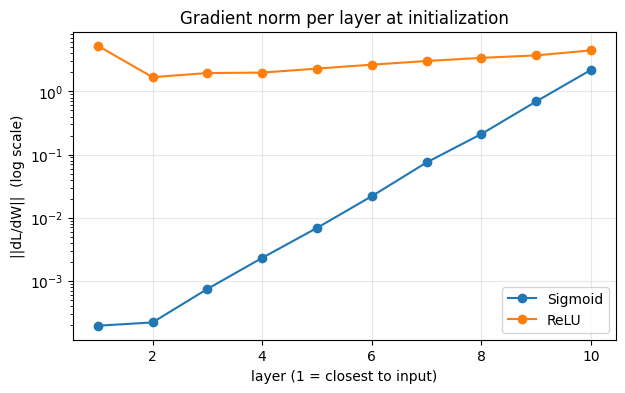

Sigmoid ['1.9e-04', '2.2e-04', '7.4e-04', '2.3e-03', '6.9e-03', '2.2e-02', '7.5e-02', '2.1e-01', '6.9e-01', '2.2e+00']
ReLU ['5.3e+00', '1.7e+00', '2.0e+00', '2.0e+00', '2.3e+00', '2.7e+00', '3.0e+00', '3.4e+00', '3.7e+00', '4.5e+00']


In [12]:
xb, yb = next(iter(train_loader))
xb = xb.to(device).view(xb.size(0), -1); yb = yb.to(device)
sizes = [3072] + [256] * 9 + [10]          # 10 Linear layers

norms = {}
for act in [Sigmoid, ReLU]:
    set_seed(42)                           # identical initial weights for both
    net = MLP(sizes, act=act)
    # TODO: one forward (loss) and one backward pass, NO update
    net.loss(xb, yb)
    net.backward()
    norms[act.__name__] = [l.dW.norm().item() for l in net.linears()]   # list of dW.norm() for each Linear layer

plt.figure(figsize=(7, 4))
for name, v in norms.items():
    plt.semilogy(range(1, 11), v, 'o-', label=name)
plt.xlabel('layer (1 = closest to input)'); plt.ylabel('||dL/dW||  (log scale)')
plt.title('Gradient norm per layer at initialization'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
for name, v in norms.items():
    print(name, ['%.1e' % g for g in v])

#### Interpretation:
**Sigmoid:** the norm falls from 2.2 at layer 10 to 1.9e-4 at layer 1, a drop of about 10,000×. Going backward, each layer's gradient is multiplied by the sigmoid derivative (at most 0.25) and by Wᵀ. The numbers show a drop of roughly 3× per layer, and ten layers of that compounds. So layer 1 learns about ten thousand times more slowly than layer 10 at the same learning rate, causing the **vanishing gradient problem**.

**ReLU:** the norms stay between about 1.7 and 5.3, the same order of magnitude across all layers. ReLU's derivative is exactly 1 for active neurons, and He initialization keeps the signal's scale stable, so nothing shrinks as it flows back.